# Eksploracyjna Analiza Danych

Praca ma na celu zbadanie atrakcyjności turystycznej bałkańskich regionów NUTS2. Pod uwagę zostaną wzięte zmienne:
- Liczba zarezerwowanych noclegów ogółem
- Ilość noclegów zarezerwowanych przez osoby zza granicy (do późniejszego wyliczenia stosunku ich do ogółu)
- Liczba obiektów
- Ruch lotniczy (dla regionów posiadających lotniska)
- Poziom cen dla sektoru turystycznego (raportowany na poziomie NUTS0)
- Jakość wód kąpielowych (NUTS0)


#Wczytanie potrzebnych bibliotek

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Wczytanie danych

In [25]:
df = pd.read_excel('baza_balkany.xlsx')
pd.set_option('display.float_format', lambda x: '%.2f' % x)


Przyjrzyjmy się jakie dokładnie mamy dane w zbiorze

In [26]:
df.describe()


,Year,Noclegi_Ogolem,Noclegi_Zagraniczne,Liczba_Obiektow,Ruch_Lotniczy,Poziom_Cen_NUTS0,Wody_Doskonała_Jakość_NUTS0
count,263.00,263.00,263.00,263.00,263.00,263.00,263.00
mean,2021.08,4452285.19,3161155.49,4679.50,2739.68,66.94,718.61
std,2.00,6421048.55,6164450.10,16838.99,4917.74,14.88,740.09
min,2018.00,140050.00,18207.00,112.00,0.00,47.60,21.00
25%,2019.00,1050736.00,242119.00,680.00,5.63,53.20,49.50
50%,2021.00,2073709.00,760828.00,1187.00,582.06,62.90,113.00
75%,2023.00,4259930.00,2115299.00,2462.00,3270.53,83.90,1631.00
max,2024.00,32447938.00,30600629.00,115285.00,31599.50,91.00,1728.00


In [18]:
df.dtypes

geo                             object
Year                             int64
Noclegi_Ogolem                   int64
Noclegi_Zagraniczne              int64
Liczba_Obiektow                  int64
Ruch_Lotniczy                  float64
NUTS0                           object
Poziom_Cen_NUTS0               float64
Wody_Doskonała_Jakość_NUTS0      int64
dtype: object

Sprawdźmy czy pojawiają się braki danych

In [27]:
df.isnull().sum()

geo                            0
Year                           0
Noclegi_Ogolem                 0
Noclegi_Zagraniczne            0
Liczba_Obiektow                0
Ruch_Lotniczy                  0
NUTS0                          0
Poziom_Cen_NUTS0               0
Wody_Doskonała_Jakość_NUTS0    0
dtype: int64

Zbadajmy teraz unikalność danych 

In [28]:
df.nunique() / len(df) * 100

geo                            15.59
Year                            2.66
Noclegi_Ogolem                100.00
Noclegi_Zagraniczne           100.00
Liczba_Obiektow                95.06
Ruch_Lotniczy                  76.43
NUTS0                           2.66
Poziom_Cen_NUTS0               15.59
Wody_Doskonała_Jakość_NUTS0     6.84
dtype: float64

Badanie korelacji, zmienne nie mogą być współliniowe

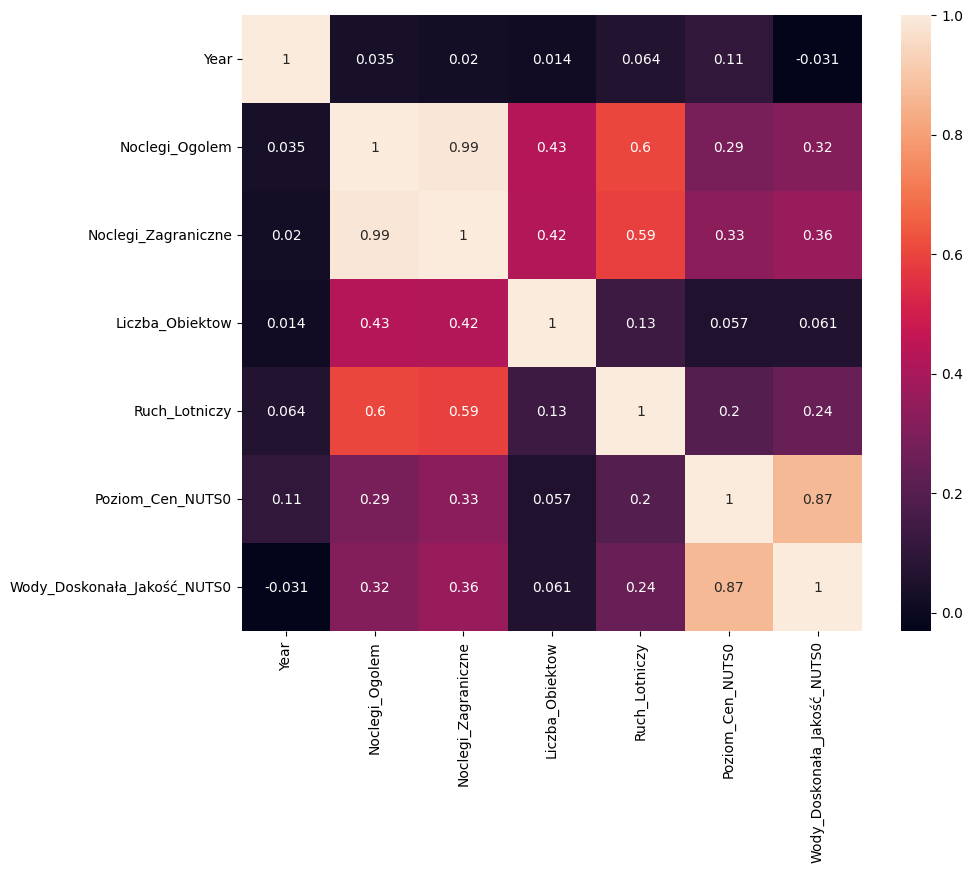

In [29]:
plt.rcParams['figure.figsize'] = (10, 8)
sns.heatmap(df.corr(numeric_only=True), annot=True)    
plt.show()

Co oczywiste zmienna noclegi zagraniczne ma korelację bliską 1 z noclegami ogółem. Jest ona jednak tylko zmienną pomocniczą, którą wykorzystamy do wyliczenia stosunku. Pozostałe zmienne nie są silnie skorelowane.

Zobaczmy jaki obszar był ogółem najpopularniejszy

In [30]:
grouped_df = df.groupby('geo')['Noclegi_Ogolem'].sum()
grouped_df.sort_values(ascending=False).head(n=10)


geo
EL42    176054311
EL43    164293586
HR03    131793169
EL62     75859483
EL52     62658438
EL30     60910934
BG34     56723915
BG33     39351788
RO22     37510926
RO12     27719806
Name: Noclegi_Ogolem, dtype: int64

Jest to region Południowe Wyspy Egejskie

In [31]:
df['Udział_Zagranicznych'] = df['Noclegi_Zagraniczne'] / df['Noclegi_Ogolem'] * 100
korelacja = df['Udział_Zagranicznych'].corr(df['Noclegi_Ogolem'])

print(f"Korelacja między udziałem zagranicznym a liczbą turystów ogółem: {korelacja:.4f}")

df = df.drop(columns=['Noclegi_Zagraniczne'])


Korelacja między udziałem zagranicznym a liczbą turystów ogółem: 0.5350
